In [1]:
import json
import random
import time
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import pandas as pd
import seaborn as sns
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

# Imports pour le Machine Learning
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm  # Pour la barre de progression

/home/infres/tandriam-25/fil_rouge/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def load_random_sample(file_path, n_samples=10000):
    """
    Charge n_samples aléatoires depuis un fichier JSONL géant sans exploser la RAM.
    """
    print(f"📂 Analyse du fichier géant : {file_path}...")

    # --- ÉTAPE 1 : COMPTAGE (Le Repérage) ---
    # On lit le fichier une première fois juste pour compter les lignes.
    # C'est très rapide car on ne stocke rien en mémoire.
    total_lines = 0
    with open(file_path, 'r', encoding='utf-8') as f:
        for _ in f:
            total_lines += 1

    print(f"📊 Total détecté : {total_lines:,} lignes.")

    # Si le fichier est plus petit que l'échantillon demandé, on prend tout
    if n_samples >= total_lines:
        probability = 1.0
    else:
        # On calcule la probabilité qu'une ligne soit choisie
        # Ex: Si on veut 1000 lignes sur 10 000, P = 0.1 (10% de chance)
        # On prend une petite marge de sécurité (1.1) pour être sûr d'en avoir assez
        probability = (n_samples * 1.1) / total_lines

    # --- ÉTAPE 2 : LE VIDEUR (Extraction) ---
    print(f"🎲 Démarrage de l'extraction aléatoire (Target: {n_samples})...")

    data = []
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            # Le Videur lance son dé
            if random.random() > probability:
                continue # La ligne est rejetée immédiatement (n'entre pas en RAM)

            try:
                # La ligne est acceptée, on la décode
                obj = json.loads(line)
                data.append(obj)
            except json.JSONDecodeError:
                continue # On ignore les lignes corrompues

    # --- ÉTAPE 3 : FINALISATION ---
    # On convertit en DataFrame
    df = pd.DataFrame(data)

    # Comme on a pris une marge de sécurité, on peut avoir un peu trop de lignes.
    # On coupe l'excédent pour avoir pile le nombre demandé.
    if len(df) > n_samples:
        df = df.sample(n=n_samples, random_state=42)

    print(f"✅ Succès ! DataFrame créé avec {len(df)} lignes.")
    return df

📂 Analyse du fichier géant : dataset/train.jsonl...
📊 Total détecté : 8,000,000 lignes.
🎲 Démarrage de l'extraction aléatoire (Target: 100000)...
✅ Succès ! DataFrame créé avec 100000 lignes.


,productid,designation,prdtypecode,typelabel,producttype,description
8092,10404005138,2 Pièces Bouchons De Trou Bouchons De Couvertu...,1780,Accessoires auto,[Poignée de portière],"La description: Convient pour LC 2014-2018, po..."
28137,13484157185,Pommes de douche Tete de Douche Inox Pommeau d...,1620,Bricolage,[Douchette],"Look Tendance Et Beau, Pomme De Douche De Qual..."
67395,9024166126,Appât Dur Flottant Bionique Pour La Pêche En P...,1760,Matériel de sport,[Appât et amorce],Description:Nom: Flottant MinoCouleur: 6 coule...
17617,11115123091,Boho Strass Corps Cha?Ne Couches Nombril Cha?N...,50,Accessoires jeux vidéo,[Pack d'accessoires],La cha?ne de taille boh¿¿me en forme de c?ur e...
108271,362738199,Teen Titans,30,Vidéo,[DVD Zone 1],Teen Titans: The Complete Seasons 1 5: Teen Ti...



📊 Analyse de fréquence sur l'échantillon aléatoire :


/tmp/ipykernel_1751441/3822728815.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=x, y=y, palette="viridis")


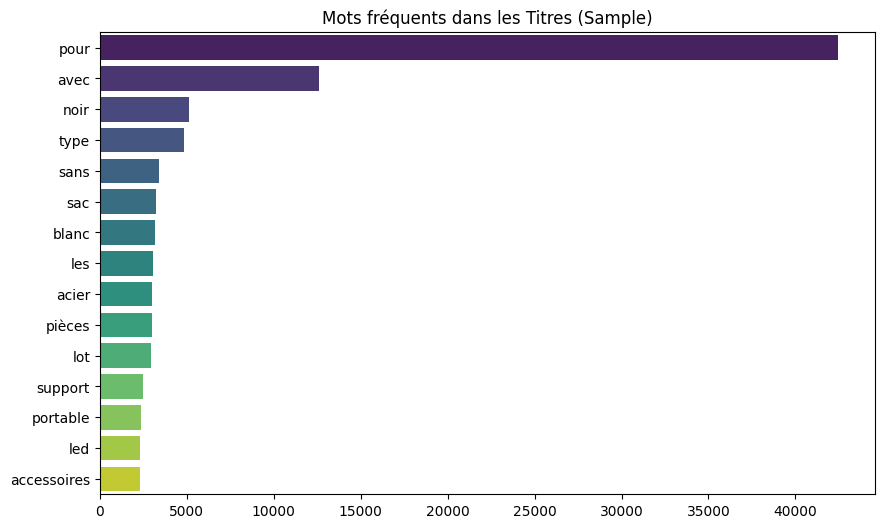

In [3]:
# --- UTILISATION ---
# Remplace par le chemin de ton GROS fichier (ex: 'train.jsonl')
# Pour l'exemple ici, j'utilise le petit fichier que tu m'as envoyé
filename = "dataset/train.jsonl"

# Disons qu'on veut extraire 3 échantillons au hasard (sur les 5 dispos)
# Sur ton vrai fichier, tu mettras n_samples=10000 ou 50000
df_sample = load_random_sample(filename, n_samples=100000)

# Affichage du résultat
display(df_sample.head())

# --- ANALYSE DE FRÉQUENCE RAPIDE SUR CET ÉCHANTILLON ---

# On refait ta visualisation de fréquence sur ce nouvel échantillon
def plot_top_words_simple(texts, title):
    all_text = " ".join(texts.astype(str)).lower()
    words = all_text.split()
    # On filtre les mots très courts pour y voir clair
    words = [w for w in words if len(w) > 2]

    counter = Counter(words)
    most_common = counter.most_common(15)

    x = [val[1] for val in most_common]
    y = [val[0] for val in most_common]

    plt.figure(figsize=(10, 6))
    sns.barplot(x=x, y=y, palette="viridis")
    plt.title(title)
    plt.show()

# On lance la visu sur la description
print("\n📊 Analyse de fréquence sur l'échantillon aléatoire :")
plot_top_words_simple(df_sample['designation'], "Mots fréquents dans les Titres (Sample)")

In [7]:
def run_tfidf_benchmark(df):
    print("\n🚀 Démarrage du Benchmark TF-IDF...")
    print("ℹ️ Note: Scikit-learn utilise le CPU. L'option n_jobs=-1 active tous les cœurs.")

    # 0. STOPWORDS
    print("📚 Chargement des stopwords (FR + EN)...")
    try: nltk.data.find('corpora/stopwords')
    except LookupError: nltk.download('stopwords')
    stop_words_custom = list(set(stopwords.words('french') + stopwords.words('english')))

    # 1. PRÉPARATION
    print("🛠️ Nettoyage des données...")
    df['clean_type'] = df['producttype'].apply(lambda x: " ".join(x) if isinstance(x, list) else (str(x) if x else ""))
    df['designation'] = df['designation'].fillna("")
    df['text_features'] = df['designation'] + " " + df['clean_type']

    # 2. SPLIT
    print("✂️ Split Train/Test...")
    X_train, X_test, y_train, y_test = train_test_split(
        df['text_features'], df['typelabel'], test_size=0.2, random_state=42
    )
    print(f"   -> Train: {len(X_train)} | Test: {len(X_test)}")

    # 3. VECTORISATION (On sort du Pipeline pour voir la barre de progression)
    print("🔠 Vectorisation TF-IDF (Cela peut prendre un moment)...")
    tfidf = TfidfVectorizer(max_features=10000, stop_words=stop_words_custom)

    # On utilise fit_transform et on chronomètre
    start_vec = time.time()
    X_train_vec = tfidf.fit_transform(tqdm(X_train, desc="Vectorisation Train"))
    X_test_vec = tfidf.transform(tqdm(X_test, desc="Vectorisation Test"))
    print(f"   -> Terminé en {time.time() - start_vec:.2f}s")

    # 4. ENTRAÎNEMENT (Avec verbose=1)
    print("🧠 Entraînement LogisticRegression (Regardez les logs ci-dessous)...")

    # verbose=1 force l'affichage de la progression interne de liblinear/lbfgs
    clf = LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        n_jobs=-1,
        verbose=1  # <--- C'est ICI que ça change tout !
    )

    start_train = time.time()
    clf.fit(X_train_vec, y_train)
    print(f"✅ Entraînement terminé en {time.time() - start_train:.2f}s")

    # 5. ÉVALUATION
    print("🔮 Prédiction...")
    y_pred = clf.predict(X_test_vec)

    f1_macro = f1_score(y_test, y_pred, average='macro')
    f1_weighted = f1_score(y_test, y_pred, average='weighted')

    print("\n" + "="*30)
    print("🏆 RÉSULTATS DU BENCHMARK TF-IDF")
    print("="*30)
    print(f"✅ F1-Score Macro    : {f1_macro:.2%}")
    print(f"💰 F1-Score Weighted : {f1_weighted:.2%}")
    print("-" * 30)
    print(classification_report(y_test, y_pred))

    return tfidf, clf

In [8]:
tfidf_model, clf_model = run_tfidf_benchmark(df_sample)


🚀 Démarrage du Benchmark TF-IDF...
ℹ️ Note: Scikit-learn utilise le CPU. L'option n_jobs=-1 active tous les cœurs.
📚 Chargement des stopwords (FR + EN)...
🛠️ Nettoyage des données...
✂️ Split Train/Test...
   -> Train: 80000 | Test: 20000
🔠 Vectorisation TF-IDF (Cela peut prendre un moment)...


Vectorisation Test: 100%|██████████| 20000/20000 [00:00<00:00, 60704.14it/s]
/home/infres/tandriam-25/fil_rouge/venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


   -> Terminé en 2.07s
🧠 Entraînement LogisticRegression (Regardez les logs ci-dessous)...
✅ Entraînement terminé en 72.92s
🔮 Prédiction...

🏆 RÉSULTATS DU BENCHMARK TF-IDF
✅ F1-Score Macro    : 79.36%
💰 F1-Score Weighted : 81.42%
------------------------------
                                              precision    recall  f1-score   support

                     Accessoires Audio Vidéo       0.79      0.65      0.71       252
            Accessoires WC et salle de bains       0.67      0.96      0.79       165
                      Accessoires animalerie       0.94      0.88      0.91       580
                            Accessoires auto       0.92      0.77      0.84      1204
            Accessoires cycle et cyclomoteur       0.84      0.84      0.84       833
                    Accessoires de rangement       0.61      0.90      0.73       122
                      Accessoires jeux vidéo       0.88      0.70      0.78       201
                         Accessoires mobiles     

/home/infres/tandriam-25/fil_rouge/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/infres/tandriam-25/fil_rouge/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/infres/tandriam-25/fil_rouge/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{m

In [26]:
start = time.time()
vec = tfidf_model.transform(["Les 3 mousquetaires"])
pred = clf_model.predict(vec)[0]
proba = clf_model.predict_proba(vec).max()

print(f"🤖 Prédiction : \033[1m{pred}\033[0m") # En gras
print(f"📊 Confiance  : {proba:.1%}")
print(f"⏱️ Temps      : {(time.time()-start)*1000:.1f} ms")

🤖 Prédiction : Livres
📊 Confiance  : 2.7%
⏱️ Temps      : 18.6 ms
